# Hedge profiles: where Merton's hedge and the quadratic hedge differ

This notebook looks at the two hedge ratios as functions of the state $x$, before any simulation. It asks four questions. What do the hedges look like for the four portfolios? How does the gap depend on time to expiry and on the jump share of the variance? Why does Merton's hedge become so steep when jumps dominate? And can the two hedges disagree in sign?

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
sys.path.insert(0, str(ROOT))
from jdhedge import Model, PAYOFFS, value_and_delta, quadratic_hedge, terminal_payoff
from jdhedge.pricing import components, poisson_weights

FIGURES = ROOT / "figures"
T = 1.0
base = Model(sigma=0.20, lam=2.0, m=0.0, delta=0.30)
x = np.linspace(-1.2, 1.2, 1201)
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False})

## 1. The four portfolios

Halfway to maturity, with the base parameters (jump share $\lambda\delta^2/\sigma^2 = 4.5$). The quadratic hedge is visibly smoother than Merton's. It replaces the local slope of the value function by a slope averaged over the moves a jump could produce.

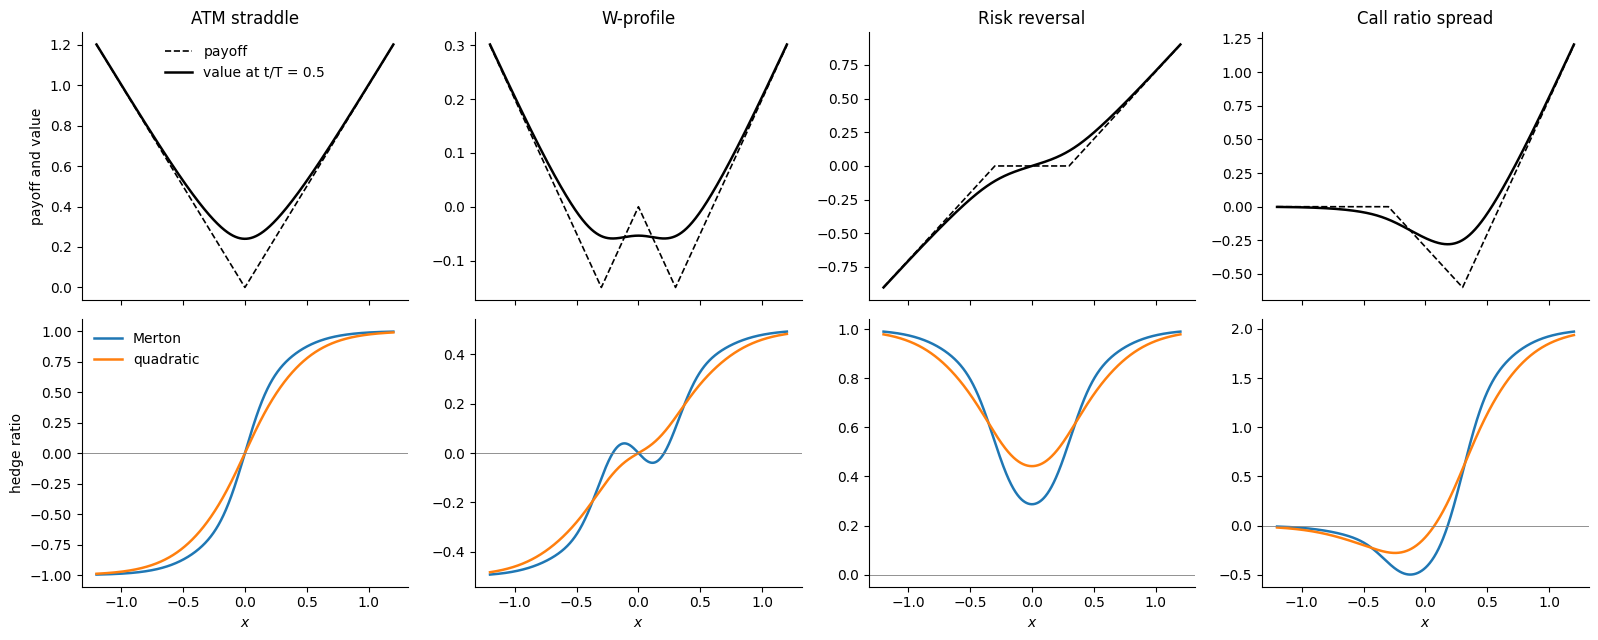

In [2]:
fig, axes = plt.subplots(2, 4, figsize=(16, 6.5), sharex=True)
for j, (name, payoff) in enumerate(PAYOFFS.items()):
    value, merton = value_and_delta(0.5, x, T, base, payoff)
    quad = quadratic_hedge(0.5, x, T, base, payoff)
    axes[0, j].plot(x, terminal_payoff(x, payoff), "k--", lw=1.2, label="payoff")
    axes[0, j].plot(x, value, "k", lw=1.8, label="value at t/T = 0.5")
    axes[0, j].set_title(name)
    axes[1, j].plot(x, merton, lw=1.8, label="Merton")
    axes[1, j].plot(x, quad, lw=1.8, label="quadratic")
    axes[1, j].axhline(0, color="grey", lw=0.6)
    axes[1, j].set_xlabel("$x$")
axes[0, 0].legend(frameon=False)
axes[1, 0].legend(frameon=False)
axes[0, 0].set_ylabel("payoff and value")
axes[1, 0].set_ylabel("hedge ratio")
fig.tight_layout()
fig.savefig(FIGURES / "hedge_profiles.png", dpi=150, bbox_inches="tight")
plt.show()

## 2. Close to expiry

For an ATM straddle, Merton's hedge converges to the sign function as $t \to T$, because without a jump the option finishes on one side of the strike. The quadratic hedge keeps a smooth part of width about $\delta$, weighted by the jump share (see section 5 of notebook 01). This is the situation of a 0DTE option late in the session. Merton's hedge asks for a full position flip on a small move through the strike, while the quadratic hedge accounts for the chance that a jump reverses the move.

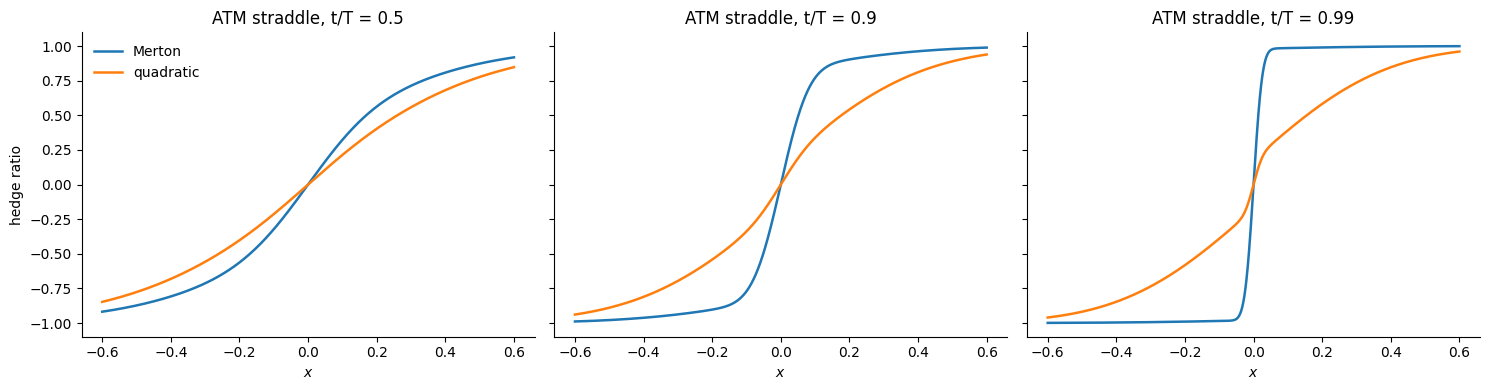

In [3]:
straddle = PAYOFFS["ATM straddle"]
xs = np.linspace(-0.6, 0.6, 1201)
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for ax, t in zip(axes, (0.5, 0.9, 0.99)):
    ax.plot(xs, value_and_delta(t, xs, T, base, straddle)[1], lw=1.8, label="Merton")
    ax.plot(xs, quadratic_hedge(t, xs, T, base, straddle), lw=1.8, label="quadratic")
    ax.set_title(f"ATM straddle, t/T = {t}")
    ax.set_xlabel("$x$")
axes[0].set_ylabel("hedge ratio")
axes[0].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "near_expiry.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. Dependence on the jump share

Keeping $\lambda = 2$ and $\delta = 0.3$ fixed and lowering $\sigma$ moves the model from diffusion-dominated to jump-dominated. When $\sigma \to 0$ the quadratic hedge tends to the pure jump regression

$$\phi^*(t, x) \to \frac{\sum_n p_n \big[m (\Pi_{n+1} - \Pi_n) + \delta^2 \Delta_{n+1}\big]}{m^2 + \delta^2},$$

which for $m = 0$ is $\sum_n p_n \Delta_{n+1}$, the delta averaged over one extra jump. Merton's hedge has no such limit. It keeps a sharp no-jump component, which is the subject of the next section.

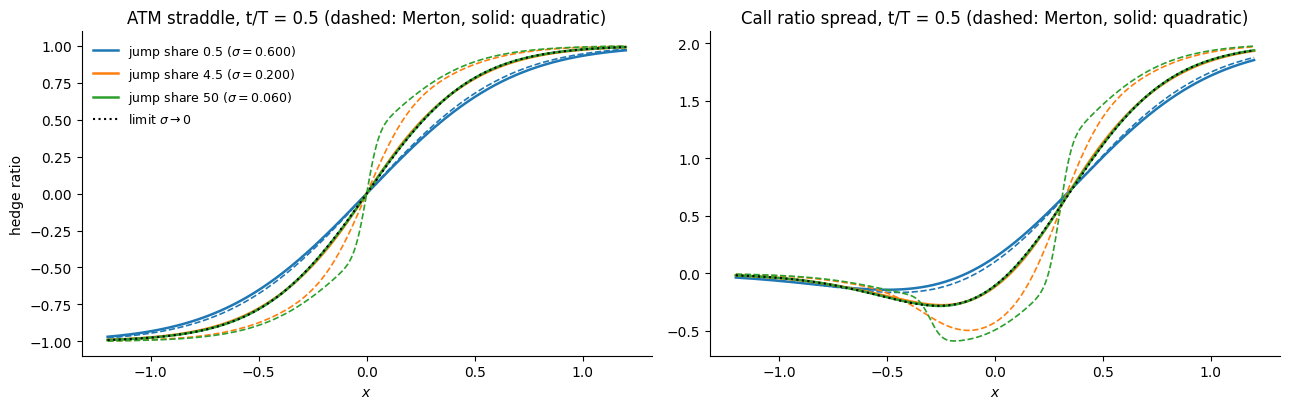

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, name in zip(axes, ("ATM straddle", "Call ratio spread")):
    payoff = PAYOFFS[name]
    for share, color in zip((0.5, 4.5, 50.0), ("C0", "C1", "C2")):
        m_ = base.replace(sigma=float(np.sqrt(base.lam * base.delta**2 / share)))
        ax.plot(x, value_and_delta(0.5, x, T, m_, payoff)[1], color=color, lw=1.2, ls="--")
        ax.plot(x, quadratic_hedge(0.5, x, T, m_, payoff), color=color, lw=1.8,
                label=rf"jump share {share:g} ($\sigma = {m_.sigma:.3f}$)")
    n, p = poisson_weights(base.lam * 0.5)
    _, deltas = components(x, np.append(n, n[-1] + 1), 0.5, base.replace(sigma=0.0), payoff)
    ax.plot(x, (p[:, None] * deltas[1:]).sum(axis=0), "k:", lw=1.5, label=r"limit $\sigma \to 0$")
    ax.set_title(f"{name}, t/T = 0.5 (dashed: Merton, solid: quadratic)")
    ax.set_xlabel("$x$")
axes[0].set_ylabel("hedge ratio")
axes[0].legend(frameon=False, fontsize=9)
fig.tight_layout()
plt.show()

## 4. Why Merton's hedge becomes steep

Merton's hedge is the Poisson-weighted average $V_x = \sum_n p_n \Delta_n$. The no-jump term has weight $p_0 = e^{-\lambda\theta}$ and variance $v_0 = \sigma^2\theta$ only. When $\sigma$ is small this term is almost a step function at each strike, and it carries a large weight (0.37 at $t/T = 0.5$ with $\lambda = 2$). The steep sections of Merton's hedge in the jump-dominated regime are therefore a genuine feature of the model and not a numerical artifact. For the parameters below, $\sqrt{v_0} = 0.013$, which the 1,201-point grid resolves.

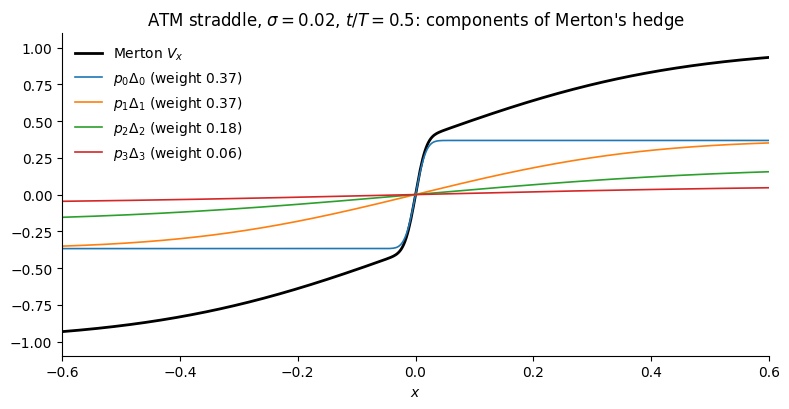

In [5]:
m_small = base.replace(sigma=0.02)
t = 0.5
n, p = poisson_weights(m_small.lam * (T - t))
_, deltas = components(x, n, T - t, m_small, straddle)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(x, (p[:, None] * deltas).sum(axis=0), "k", lw=2, label="Merton $V_x$")
for k in range(4):
    ax.plot(x, p[k] * deltas[k], lw=1.2, label=f"$p_{k} \\Delta_{k}$ (weight {p[k]:.2f})")
ax.set_xlim(-0.6, 0.6)
ax.set_xlabel("$x$")
ax.set_title(rf"ATM straddle, $\sigma = {m_small.sigma}$, $t/T = {t}$: components of Merton's hedge")
ax.legend(frameon=False)
fig.tight_layout()
plt.show()

## 5. Sign disagreement

For the call ratio spread, Merton's hedge is negative between the strikes and positive above $K$. The quadratic hedge averages the delta over possible jumps. Just below the point where the delta changes sign, a jump is likely to carry the position into the region with delta close to $+2$, and the average can already be positive. The quadratic hedge then asks to be long while Merton's hedge asks to be short.

This happens even with centered jumps ($m = 0$). It is tempting to argue that with symmetric jumps the two hedges must share a sign, but that would require the jump-averaged delta to have the sign of the local delta at every point, which fails near a sign change. Upward-biased jumps ($m > 0$) widen the region, as the table shows. It reports the width of the set of $x$ where $V_x < 0 < \phi^*$ at $t/T = 0.75$, and the largest quadratic hedge found there.

In [6]:
spread = PAYOFFS["Call ratio spread"]
xg = np.linspace(-1.5, 1.5, 3001)
rows = []
for m_ in (0.0, 0.1, 0.2, 0.5):
    for sigma in (0.3, 0.2, 0.1):
        model = Model(sigma=sigma, lam=2.0, m=m_, delta=0.30)
        merton = value_and_delta(0.75, xg, T, model, spread)[1]
        quad = quadratic_hedge(0.75, xg, T, model, spread)
        flip = (merton < 0) & (quad > 0)
        rows.append({"m": m_, "sigma": sigma, "jump share": round(model.jump_share, 2),
                     "width of disagreement": round(flip.sum() * (xg[1] - xg[0]), 3),
                     "max quadratic hedge there": round(quad[flip].max(), 3) if flip.any() else np.nan})
pd.DataFrame(rows)

,m,sigma,jump share,width of disagreement,max quadratic hedge there
0,0.0,0.3,2.00,0.065,0.206
1,0.0,0.2,4.50,0.094,0.294
2,0.0,0.1,18.00,0.144,0.417
3,0.1,0.3,2.22,0.171,0.520
4,0.1,0.2,5.00,0.228,0.727
5,0.1,0.1,20.00,0.290,0.978
6,0.2,0.3,2.89,0.273,0.772
7,0.2,0.2,6.50,0.327,1.035
8,0.2,0.1,26.00,0.390,1.346
9,0.5,0.3,7.56,0.701,1.044


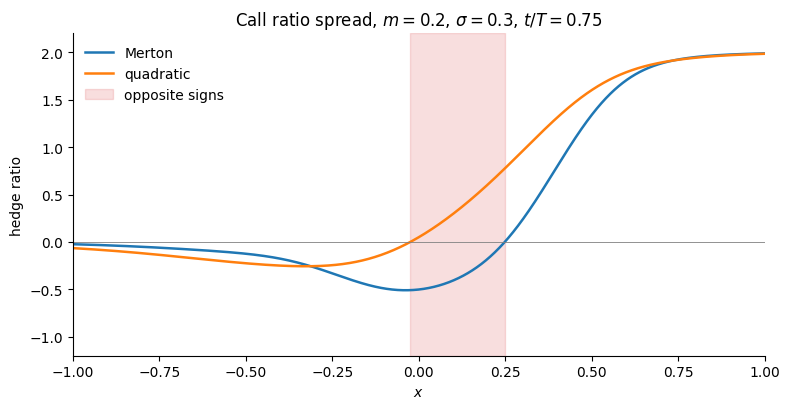

In [7]:
model = Model(sigma=0.3, lam=2.0, m=0.2, delta=0.30)
merton = value_and_delta(0.75, xg, T, model, spread)[1]
quad = quadratic_hedge(0.75, xg, T, model, spread)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.plot(xg, merton, lw=1.8, label="Merton")
ax.plot(xg, quad, lw=1.8, label="quadratic")
ax.fill_between(xg, -1.2, 2.2, where=(merton < 0) & (quad > 0), color="C3", alpha=0.15,
                label="opposite signs")
ax.axhline(0, color="grey", lw=0.6)
ax.set_ylim(-1.2, 2.2)
ax.set_xlim(-1, 1)
ax.set_xlabel("$x$")
ax.set_ylabel("hedge ratio")
ax.set_title(r"Call ratio spread, $m = 0.2$, $\sigma = 0.3$, $t/T = 0.75$")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIGURES / "sign_disagreement.png", dpi=150, bbox_inches="tight")
plt.show()